# 20 — Train & Validate Chimera v2.4

End-to-end notebook: load data, train model, run all fast diagnostics, check expectations.

**Dataset**: CAMEX liver, Human + Monkey (2-species subset)  
**Config**: D (full v2.4 with GIN, FQR, anchor, adversarial)  
**Runtime**: ~5 min training on MPS + ~30 sec diagnostics

In [1]:
import sys, os, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="scvi")

sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import anndata as ad
import torch
from pathlib import Path
from scipy.stats import spearmanr

from chimera._model import ChimeraModel
from chimera._constants import WARMUP_ADV_EPOCHS, WARMUP_FQR_EPOCHS, WARMUP_KL_EPOCHS

plt.rcParams.update({
    "figure.dpi": 120, "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
})
REPO = Path("..").resolve()
print(f"Repo: {REPO}")
print(f"PyTorch MPS: {torch.backends.mps.is_available()}")

Repo: /Users/kemalinecik/git_nosync/master_chimera/chimera
PyTorch MPS: True


## 1. Load Data & Cell Type Composition

In [2]:
# === Configuration ===
ADATA_PATH = REPO / "data" / "processed" / "camex_human_monkey.h5ad"
RUN_NAME = "nb20-best"  # will be created under training/runs/
CONFIG = "D"             # full v2.4
MAX_EPOCHS = 100
SEED = 42
ACCELERATOR = "mps"

# Hyperparameters (iter31 best recipe: MMD + masking + z-detach)
PLAN_KWARGS = dict(
    adv_weight=100, adv_lr=1e-4,
    warmup_kl_epochs=20, warmup_fqr_epochs=20, warmup_adversarial_epochs=15,
)
MODEL_OVERRIDES = dict(
    lambda_fit=0.1, lambda_anchor=0.001, lambda_res=0.01,
    lambda_mmd=1000.0,
    mask_species_in_encoder=True,
    mask_batch_in_encoder=True,
    detach_z_residual=True,
)

# Load
adata = ad.read_h5ad(ADATA_PATH)
print(f"Shape: {adata.shape}")
print(f"Species: {adata.obs['species'].value_counts().to_dict()}")
print(f"Gene features: {adata.varm['gene_features'].shape}")
print(f"Conservation prior: [{adata.var['conservation_prior'].min():.3f}, {adata.var['conservation_prior'].max():.3f}]")
print(f"p_null: {adata.uns['p_null'].shape}")

# Cell type composition
ct = adata.obs.groupby(["species", "cell_type"], observed=True).size().reset_index(name="count")
ct_pivot = ct.pivot_table(index="cell_type", columns="species", values="count", fill_value=0).astype(int)
shared_mask = (ct_pivot > 0).all(axis=1)
print(f"\nCell type composition:")
display(ct_pivot.style.apply(lambda s: ["background: #d4edda" if shared_mask[s.name] else "" for _ in s], axis=1))
print(f"\nShared cell types: {list(ct_pivot.index[shared_mask])} ({shared_mask.sum()}/{len(ct_pivot)})")
print(f"Cells in shared types: {ct_pivot[shared_mask].sum().sum()} / {adata.n_obs} ({ct_pivot[shared_mask].sum().sum()/adata.n_obs:.1%})")

Shape: (12608, 8430)
Species: {'Monkey': 8483, 'Human': 4125}
Gene features: (8430, 72)
Conservation prior: [0.164, 0.950]
p_null: (2, 8430)

Cell type composition:


species,Human,Monkey
cell_type,,
B Plasma cells,0,148
Cholangio,197,365
Endothelial,700,1455
Hepatocytes,2705,5340
Kupffer cells,0,364
Macrophages,170,0
NK NKT and T cells,0,199
fibroblasts,353,612



Shared cell types: ['Cholangio', 'Endothelial', 'Hepatocytes', 'fibroblasts'] (4/8)
Cells in shared types: 11727 / 12608 (93.0%)


## 2. Train Model

In [3]:
import time
from lightning.pytorch.callbacks import Callback
from lightning.pytorch.loggers import CSVLogger

# Reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)

# Setup anndata
ChimeraModel.setup_anndata(adata, species_key="species", batch_key="batch")

# Create model
model = ChimeraModel.from_config(adata, config_name=CONFIG, **MODEL_OVERRIDES)
print(model)

# Output directory
run_dir = REPO / "training" / "runs" / RUN_NAME
run_dir.mkdir(parents=True, exist_ok=True)

# Alpha snapshot callback
class AlphaSnapshotCallback(Callback):
    def __init__(self, module, out_dir, every_n=2):
        self.module = module
        self.out_dir = Path(out_dir) / "alpha_snapshots"
        self.out_dir.mkdir(exist_ok=True)
        self.every_n = every_n

    def on_train_epoch_end(self, trainer, pl_module):
        epoch = trainer.current_epoch
        if epoch % self.every_n != 0:
            return
        with torch.no_grad():
            m = self.module
            if hasattr(m, "per_gene_correction"):
                alpha = torch.sigmoid(torch.logit(m.conservation_prior) + m.per_gene_correction)
                correction = m.per_gene_correction.cpu().numpy()
            else:
                alpha, correction = m.gin(m.gene_features, m.conservation_prior)
                correction = correction.cpu().numpy()
            np.savez_compressed(
                self.out_dir / f"alpha_epoch_{epoch:04d}.npz",
                alpha=alpha.cpu().numpy(),
                correction=correction,
                S_g_ema=m.S_g_ema.cpu().numpy(),
            )

class StashTrainingPlanCallback(Callback):
    """Preserve training plan reference (scvi-tools drops it after train)."""
    def on_fit_start(self, trainer, pl_module):
        trainer._chimera_plan = pl_module

csv_logger = CSVLogger(save_dir=str(run_dir), name="lightning")

# Train
t0 = time.time()
model.train(
    max_epochs=MAX_EPOCHS,
    batch_size=256,
    early_stopping=False,
    plan_kwargs=PLAN_KWARGS,
    accelerator=ACCELERATOR,
    callbacks=[
        AlphaSnapshotCallback(model.module, run_dir, every_n=2),
        StashTrainingPlanCallback(),
    ],
    logger=csv_logger,
)
elapsed = time.time() - t0
print(f"Training completed in {elapsed:.1f}s ({elapsed/MAX_EPOCHS:.1f}s/epoch)")

# Save model
model.save(str(run_dir / "model"), overwrite=True)
print(f"Model saved to {run_dir / 'model'}")

ChimeraModel v2.4 | Genes: 8430, Species: 2, Batches: 3, Latent: 10, Hidden: 128


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/core/optimizer.py:317: The lr scheduler dict contains the key(s) ['monitor'], but the keys will be ignored. You need to call `lr_scheduler.step()` manually in manual optimization.
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Training:   0%|          | 0/100 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


Training completed in 318.2s (3.2s/epoch)
Model saved to /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/nb20-best/model


## 3. Extract Post-Training State

In [4]:
# Move model to CPU for inference (avoids MPS tensor mismatch)
model.module.to("cpu")

# Extract model outputs
alpha = model.get_alpha()
delta_alpha = model.get_delta_alpha()
correction = model.get_correction()
S_g = model.get_S_g()
z = model.get_latent_representation(adata)
prior = model.module.conservation_prior.cpu().numpy()

# Load training metrics
metrics_path = sorted((run_dir / "lightning").rglob("metrics.csv"))[-1]
metrics = pd.read_csv(metrics_path)

# Load alpha snapshots
snap_dir = run_dir / "alpha_snapshots"
snap_files = sorted(snap_dir.glob("alpha_epoch_*.npz"))
snapshots = [(int(f.stem.split("_")[-1]), np.load(f)) for f in snap_files]

print(f"Alpha: mean={alpha.mean():.3f}, std={alpha.std():.3f}")
print(f"Delta-alpha: [{delta_alpha.min():.3f}, {delta_alpha.max():.3f}]")
print(f"  Positive (>0.02): {(delta_alpha > 0.02).mean():.1%}")
print(f"  Negative (<-0.02): {(delta_alpha < -0.02).mean():.1%}")
print(f"S_g > 0: {(S_g > 0).mean():.1%}")
print(f"z shape: {z.shape}")
print(f"Metrics: {len(metrics)} rows, {len(snap_files)} alpha snapshots")

Alpha: mean=0.781, std=0.132
Delta-alpha: [-0.268, 0.182]
  Positive (>0.02): 26.3%
  Negative (<-0.02): 44.7%
S_g > 0: 60.7%
z shape: (12608, 10)
Metrics: 550 rows, 50 alpha snapshots


## 4. Loss Curves (All Components)

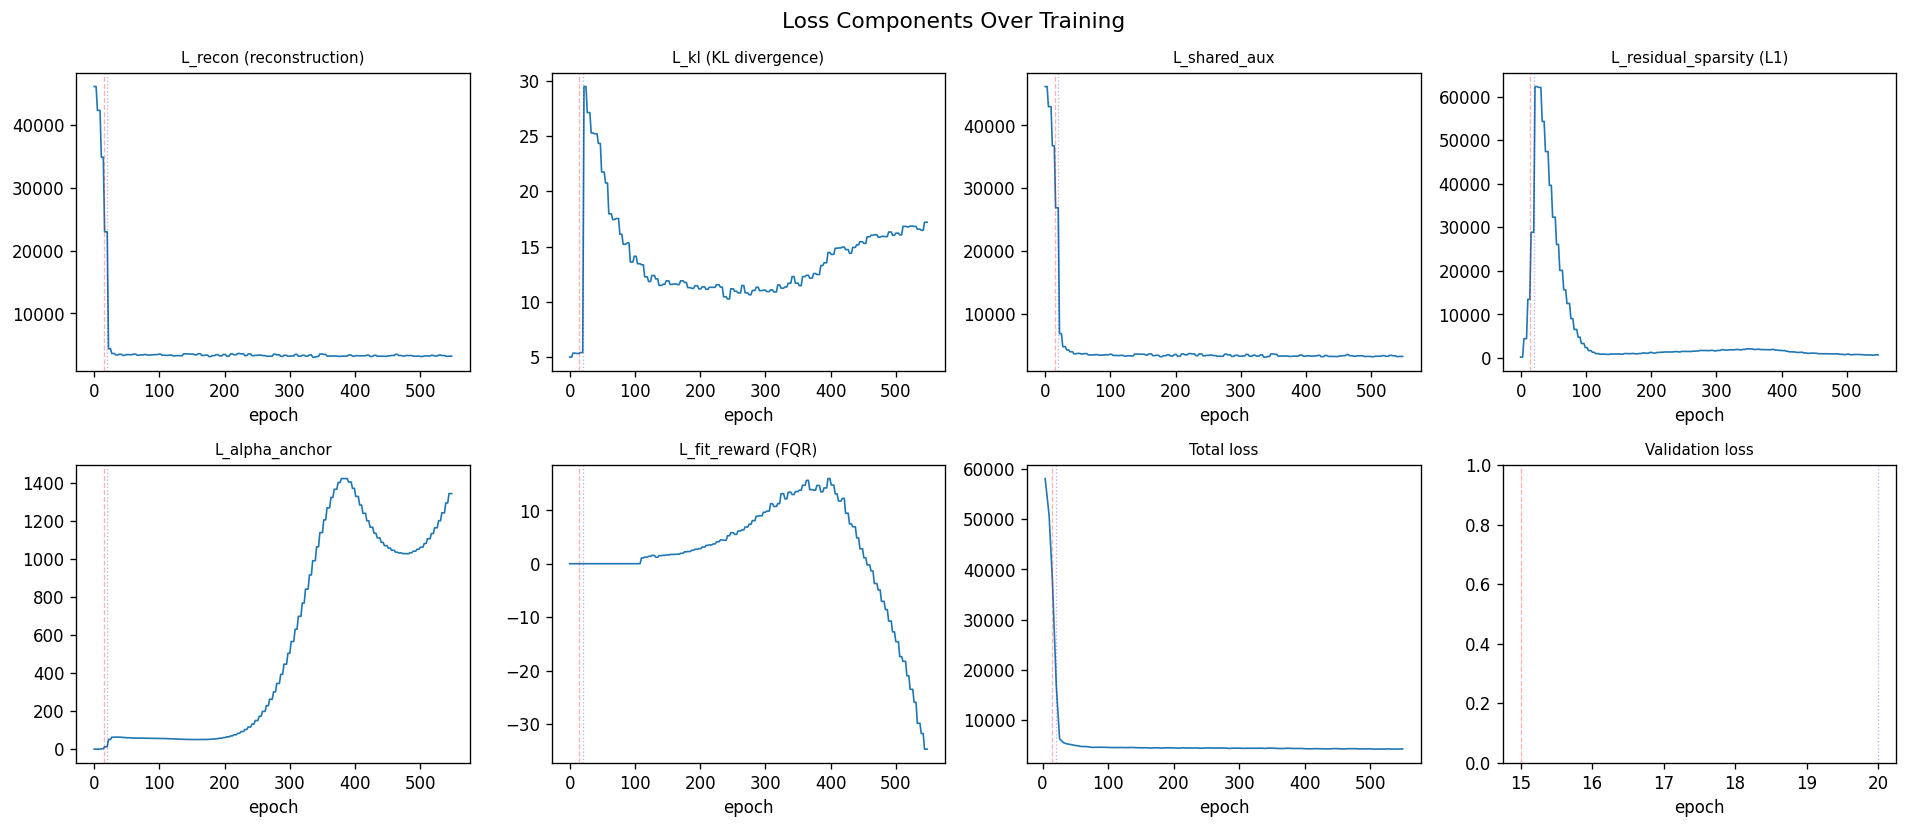

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

loss_keys = [
    ("train/L_recon", "L_recon (reconstruction)"),
    ("train/L_kl", "L_kl (KL divergence)"),
    ("train/L_shared_aux", "L_shared_aux"),
    ("train/L_residual_sparsity", "L_residual_sparsity (L1)"),
    ("train/L_alpha_anchor", "L_alpha_anchor"),
    ("train/L_fit_reward", "L_fit_reward (FQR)"),
    ("train_loss", "Total loss"),
    ("validation_loss", "Validation loss"),
]

for ax, (key, title) in zip(axes.flat, loss_keys):
    col = key.replace("/", "_") if key.replace("/", "_") in metrics.columns else key
    if col in metrics.columns:
        vals = metrics[col].dropna()
        ax.plot(vals.index, vals.values, linewidth=1)
    else:
        # Try alternate column naming
        for c in metrics.columns:
            if key.split("/")[-1] in c:
                vals = metrics[c].dropna()
                ax.plot(vals.index, vals.values, linewidth=1)
                break
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("epoch")
    # Mark warmup boundaries
    for ep, c, ls in [(WARMUP_ADV_EPOCHS, "red", "--"), (WARMUP_FQR_EPOCHS, "blue", ":")]:
        ax.axvline(ep, color=c, linestyle=ls, alpha=0.3, linewidth=0.8)

fig.suptitle("Loss Components Over Training", fontsize=13)
fig.tight_layout()
plt.show()

## 5. Alpha Histogram Evolution

Alpha should evolve from all-at-prior (epoch 0) to a spread distribution. Check for:
- FM1: all alpha near 0 (residual absorbs everything)
- FM3: bimodal at prior and ~0 (no interior equilibrium)
- FM4: one-directional delta-alpha (all below prior)

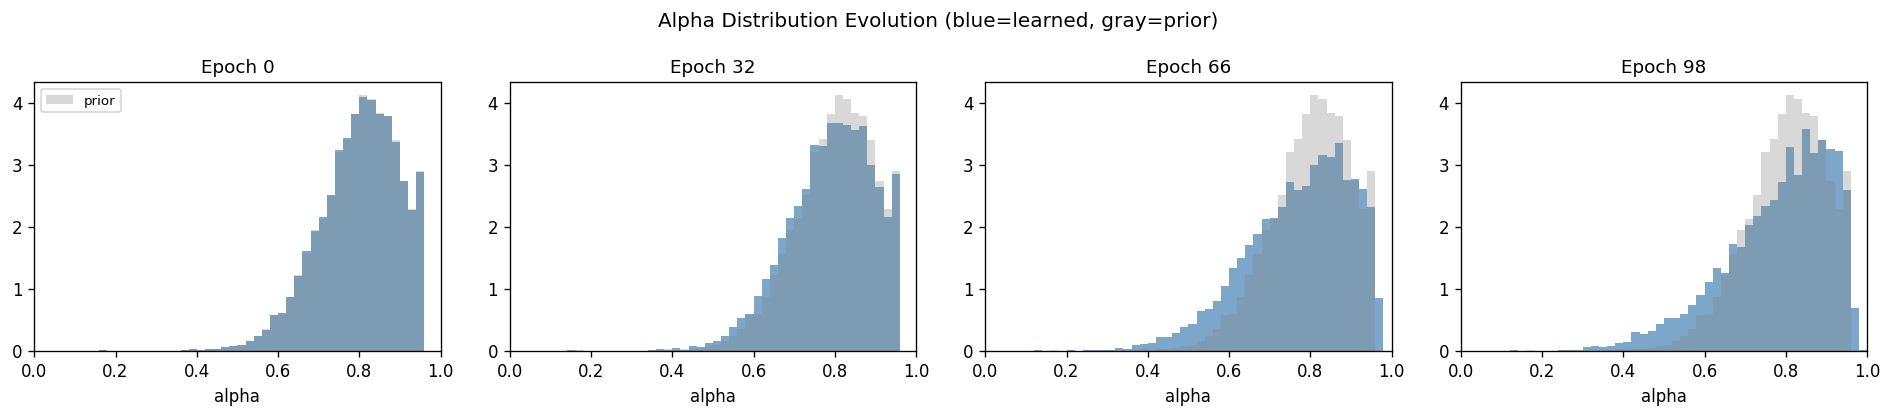

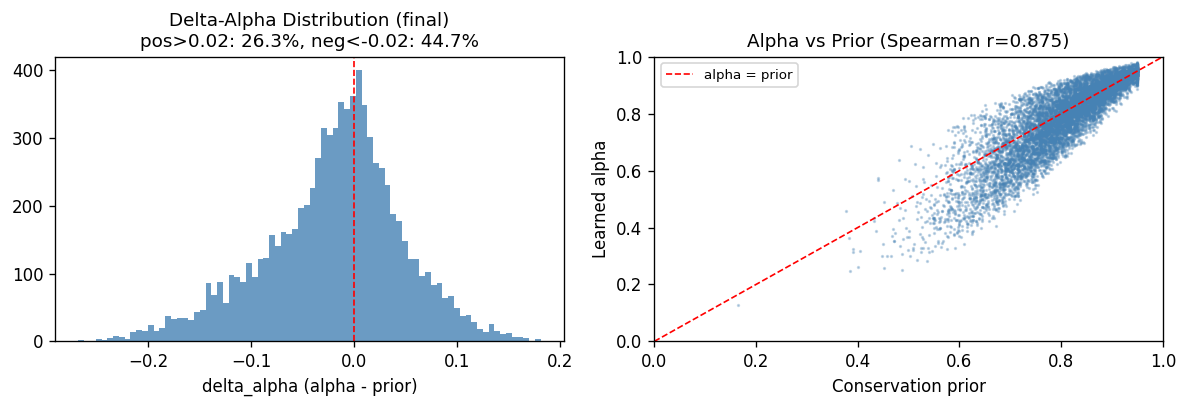

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))

# Pick 4 representative epochs
pick_epochs = [0, len(snapshots)//3, 2*len(snapshots)//3, len(snapshots)-1]
for ax, idx in zip(axes, pick_epochs):
    ep, snap = snapshots[idx]
    a = snap["alpha"]
    ax.hist(a, bins=50, range=(0, 1), alpha=0.7, density=True, color="steelblue", edgecolor="none")
    ax.hist(prior, bins=50, range=(0, 1), alpha=0.3, density=True, color="gray",
            edgecolor="none", label="prior")
    ax.set_title(f"Epoch {ep}")
    ax.set_xlabel("alpha")
    ax.set_xlim(0, 1)
    if idx == 0:
        ax.legend(fontsize=8)

fig.suptitle("Alpha Distribution Evolution (blue=learned, gray=prior)", fontsize=12)
fig.tight_layout()
plt.show()

# Delta-alpha distribution at final epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

ax1.hist(delta_alpha, bins=80, color="steelblue", edgecolor="none", alpha=0.8)
ax1.axvline(0, color="red", linestyle="--", linewidth=1)
ax1.set_xlabel("delta_alpha (alpha - prior)")
ax1.set_title(f"Delta-Alpha Distribution (final)\npos>0.02: {(delta_alpha>0.02).mean():.1%}, neg<-0.02: {(delta_alpha<-0.02).mean():.1%}")

# Alpha vs prior scatter
ax2.scatter(prior, alpha, s=1, alpha=0.3, c="steelblue", rasterized=True)
ax2.plot([0, 1], [0, 1], "r--", linewidth=1, label="alpha = prior")
ax2.set_xlabel("Conservation prior")
ax2.set_ylabel("Learned alpha")
ax2.set_title(f"Alpha vs Prior (Spearman r={spearmanr(prior, alpha).correlation:.3f})")
ax2.legend(fontsize=8)
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)

fig.tight_layout()
plt.show()

## 6. Adversarial Training & Z-Leakage

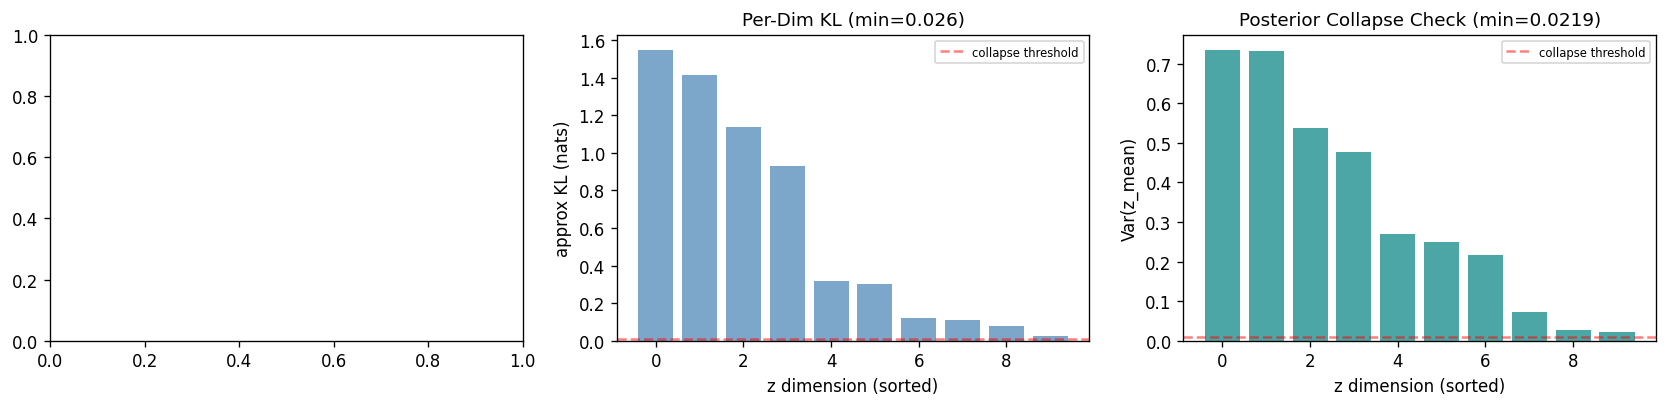

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

# Adversarial accuracy trajectory
adv_col = [c for c in metrics.columns if "adversarial_accuracy" in c]
if adv_col:
    adv = metrics[adv_col[0]].dropna()
    n_sp = len(adata.obs["species"].unique())
    axes[0].plot(adv.index, adv.values, linewidth=1, color="orangered")
    axes[0].axhline(1.0/n_sp, color="green", linestyle="--", alpha=0.5, label=f"chance={1/n_sp:.2f}")
    axes[0].axhline(0.5*(1+1/n_sp), color="gray", linestyle=":", alpha=0.5, label="midpoint")
    axes[0].axvline(WARMUP_ADV_EPOCHS, color="red", linestyle="--", alpha=0.3)
    axes[0].set_title("Adversarial Accuracy")
    axes[0].set_xlabel("epoch")
    axes[0].legend(fontsize=7)
    axes[0].set_ylim(0, 1)

# Per-dim KL
kl_per_dim = 0.5 * (z.mean(0)**2 + z.var(0) - np.log(z.var(0) + 1e-8) - 1)
axes[1].bar(range(len(kl_per_dim)), sorted(kl_per_dim, reverse=True), color="steelblue", alpha=0.7)
axes[1].axhline(0.01, color="red", linestyle="--", alpha=0.5, label="collapse threshold")
axes[1].set_xlabel("z dimension (sorted)")
axes[1].set_ylabel("approx KL (nats)")
axes[1].set_title(f"Per-Dim KL (min={kl_per_dim.min():.3f})")
axes[1].legend(fontsize=7)

# Var(z_mean) per dim — posterior collapse check
z_var = z.var(axis=0)
axes[2].bar(range(len(z_var)), sorted(z_var, reverse=True), color="teal", alpha=0.7)
axes[2].axhline(0.01, color="red", linestyle="--", alpha=0.5, label="collapse threshold")
axes[2].set_xlabel("z dimension (sorted)")
axes[2].set_ylabel("Var(z_mean)")
axes[2].set_title(f"Posterior Collapse Check (min={z_var.min():.4f})")
axes[2].legend(fontsize=7)

fig.tight_layout()
plt.show()

## 7. Residual L-Shape & S_g Analysis

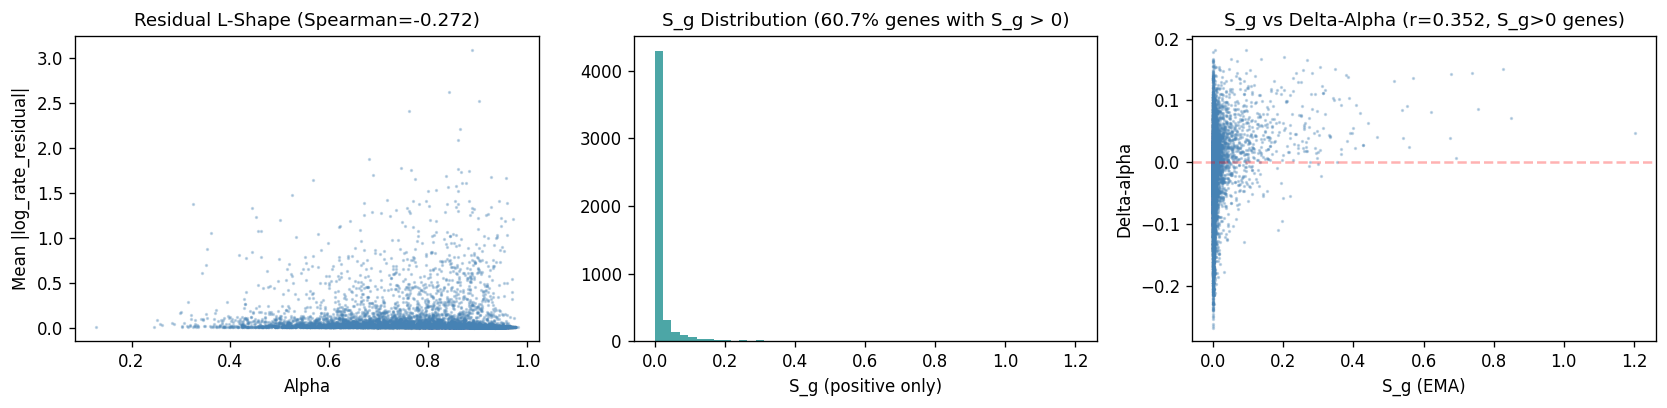

In [8]:
# Compute per-gene residual magnitude from a forward pass
model.module.eval()
with torch.no_grad():
    # Get a representative batch
    dl = model._make_data_loader(adata=adata, batch_size=512, shuffle=False)
    residual_mag = np.zeros(adata.n_vars)
    n_batches = 0
    for tensors in dl:
        x = tensors["X"]
        sp_idx = tensors["labels"].squeeze(-1).long()
        b_idx = tensors["batch"].squeeze(-1).long()
        sp_oh = torch.nn.functional.one_hot(sp_idx, model.module.n_species).float()
        b_oh = torch.nn.functional.one_hot(b_idx, model.module.n_batch).float()
        enc_in = model.module._encoder_input(x, sp_oh, b_oh)
        h_enc = model.module.encoder(enc_in)
        z_mean = model.module.z_mean_linear(h_enc)
        h = model.module.decoder_hidden(z_mean)
        lr_res = model.module.output_residual(torch.cat([h, sp_oh, b_oh], dim=-1))
        residual_mag += lr_res.abs().mean(0).cpu().numpy()
        n_batches += 1
    residual_mag /= n_batches

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

# Residual L-shape
axes[0].scatter(alpha, residual_mag, s=1, alpha=0.3, c="steelblue", rasterized=True)
axes[0].set_xlabel("Alpha")
axes[0].set_ylabel("Mean |log_rate_residual|")
r_sp = spearmanr(alpha, residual_mag).correlation
axes[0].set_title(f"Residual L-Shape (Spearman={r_sp:.3f})")

# S_g distribution
axes[1].hist(S_g[S_g > 0], bins=50, color="teal", alpha=0.7, edgecolor="none")
axes[1].set_xlabel("S_g (positive only)")
axes[1].set_title(f"S_g Distribution ({(S_g>0).mean():.1%} genes with S_g > 0)")

# S_g vs delta_alpha
axes[2].scatter(S_g, delta_alpha, s=1, alpha=0.3, c="steelblue", rasterized=True)
mask = S_g > 0
if mask.sum() > 10:
    r_sg = spearmanr(S_g[mask], delta_alpha[mask]).correlation
    axes[2].set_title(f"S_g vs Delta-Alpha (r={r_sg:.3f}, S_g>0 genes)")
else:
    axes[2].set_title("S_g vs Delta-Alpha")
axes[2].set_xlabel("S_g (EMA)")
axes[2].set_ylabel("Delta-alpha")
axes[2].axhline(0, color="red", linestyle="--", alpha=0.3)

fig.tight_layout()
plt.show()

## 8. Training Schedule Diagnostics

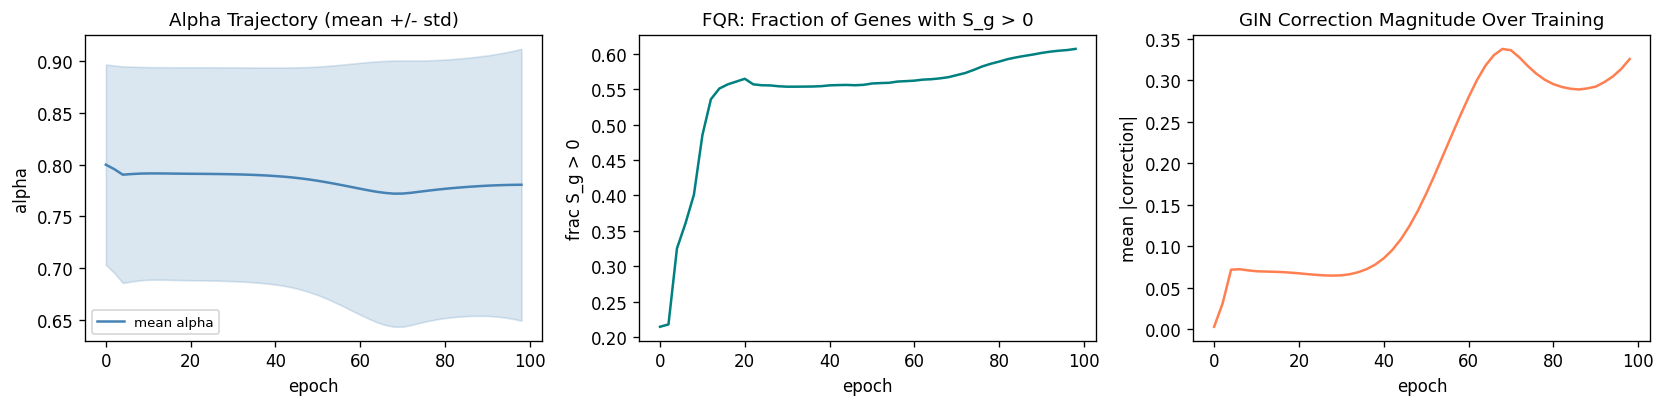

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

# Alpha trajectory (mean + std band)
alpha_means = [snap["alpha"].mean() for _, snap in snapshots]
alpha_stds = [snap["alpha"].std() for _, snap in snapshots]
epochs = [ep for ep, _ in snapshots]
axes[0].plot(epochs, alpha_means, color="steelblue", label="mean alpha")
axes[0].fill_between(epochs,
    [m - s for m, s in zip(alpha_means, alpha_stds)],
    [m + s for m, s in zip(alpha_means, alpha_stds)],
    alpha=0.2, color="steelblue")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("alpha")
axes[0].set_title("Alpha Trajectory (mean +/- std)")
axes[0].legend(fontsize=8)

# S_g fraction positive over time
sg_fracs = [(S_snap["S_g_ema"] > 0).mean() for _, S_snap in snapshots]
axes[1].plot(epochs, sg_fracs, color="teal")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("frac S_g > 0")
axes[1].set_title("FQR: Fraction of Genes with S_g > 0")

# Correction magnitude over time
corr_means = [np.abs(snap["correction"]).mean() for _, snap in snapshots]
axes[2].plot(epochs, corr_means, color="coral")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("mean |correction|")
axes[2].set_title("GIN Correction Magnitude Over Training")

fig.tight_layout()
plt.show()

## 9. Expectation Gate (Pass/Fail Table)

Inline evaluation of all 32 pre-registered expectations from `workflow.md`.

In [10]:
from scipy.stats import spearmanr as _spearmanr

def _bimodality_coefficient(x):
    x = np.asarray(x, dtype=np.float64).ravel()
    n = x.size
    if n < 3: return 0.0
    m, s = x.mean(), x.std(ddof=1)
    if s < 1e-12: return 0.0
    z = (x - m) / s
    g1 = (z**3).mean()
    g2 = (z**4).mean() - 3.0
    return (g1**2 + 1) / (g2 + 3*(n-1)**2/((n-2)*(n-3) + 1e-12))

results = []

def check(eid, name, value, threshold, passed):
    results.append({"ID": eid, "Name": name, "Value": f"{value}", "Pass": passed})

# E1 pretraining (basic checks)
gf = adata.varm["gene_features"]
gf_std = gf.std(axis=0)
active = gf_std > 1e-6
check("E1.2", "gene_features_normalized", f"{active.sum()} active features", "std in [0.5,2]",
      all(0.5 <= gf_std[active]) and all(gf_std[active] <= 2.0))

cp = adata.var["conservation_prior"].values
check("E1.5", "prior_range", f"[{cp.min():.3f}, {cp.max():.3f}], std={cp.std():.3f}",
      "min<0.3, max>0.7, std>0.05", cp.min() < 0.3 and cp.max() > 0.7 and cp.std() > 0.05)

# E2 dynamics
train_loss_col = [c for c in metrics.columns if c == "train_loss"][0] if "train_loss" in metrics.columns else None
if train_loss_col:
    tl = metrics[train_loss_col].dropna()
    check("E2.1", "loss_finite", "no NaN/Inf", "", tl.notna().all() and np.isfinite(tl.values).all())
    check("E2.2", "loss_decreases", f"first={tl.iloc[0]:.0f}, last={tl.iloc[-1]:.0f}", "last<first", tl.iloc[-1] < tl.iloc[0])

# E3 GIN
check("E3.1", "alpha_init_is_prior", f"max|diff|={np.abs(snapshots[0][1]['alpha'] - prior).max():.4f}",
      "<= 0.05", np.abs(snapshots[0][1]["alpha"] - prior).max() <= 0.05)
check("E3.2", "alpha_healthy", f"std={alpha.std():.3f}", "std>=0.05",
      alpha.std() >= 0.05 and (alpha < 0.05).mean() <= 0.5 and (alpha > 0.95).mean() <= 0.5)
bc = _bimodality_coefficient(alpha)
check("E3.3", "no_bimodal_collapse", f"BC={bc:.3f}", "<0.85", bc < 0.85)
check("E3.4", "delta_alpha_two_sided",
      f"pos={( delta_alpha>0.02).mean():.1%}, neg={(delta_alpha<-0.02).mean():.1%}",
      "both>=5%", (delta_alpha>0.02).mean() >= 0.05 and (delta_alpha<-0.02).mean() >= 0.05)
check("E3.5", "correction_nonzero", f"mean|corr|={np.abs(correction).mean():.4f}", ">=0.01",
      np.abs(correction).mean() >= 0.01)
alpha_init = snapshots[0][1]["alpha"]
check("E3.6", "gin_learning_evolved", f"mean|delta|={np.abs(alpha - alpha_init).mean():.4f}",
      ">=0.01", np.abs(alpha - alpha_init).mean() >= 0.01)

# E4 biology
r_ap = _spearmanr(prior, alpha).correlation
check("E4.1", "alpha_correlates_prior", f"r={r_ap:.3f}", ">=0.25", r_ap >= 0.25)
r_rl = _spearmanr(alpha, residual_mag).correlation
check("E4.2", "residual_L_shape", f"Spearman={r_rl:.3f}", "<=-0.15", r_rl <= -0.15)
check("E4.3", "fqr_active_fraction", f"{(S_g>0).mean():.1%}", ">=3%", (S_g>0).mean() >= 0.03)

# E5 shared/residual
check("E5.3", "residual_has_magnitude", f"RMS={np.sqrt((residual_mag**2).mean()):.4f}",
      "[0.01, 5]", 0.01 <= np.sqrt((residual_mag**2).mean()) <= 5.0)

# E6 adversarial
if adv_col:
    adv_vals = metrics[adv_col[0]].dropna().values
    n_sp = len(adata.obs["species"].unique())
    check("E6.1", "adv_drops_from_peak",
          f"peak={adv_vals.max():.3f}, final={adv_vals[-1]:.3f}",
          "final < peak - 0.03", adv_vals[-1] < adv_vals.max() - 0.03)
    midpoint = 0.5 * (1 + 1/n_sp)
    tail = adv_vals[-10:]
    tail_below = (tail < midpoint).sum()
    check("E6.2", "adv_near_chance",
          f"final={adv_vals[-1]:.3f}, tail_below_mid={tail_below}/10",
          ">=5/10 tail below midpoint", tail_below >= 5)
    check("E6.3", "no_posterior_collapse", f"min Var(z)={z.var(0).min():.4f}",
          ">=0.01", z.var(0).min() >= 0.01)

# E7 convergence
val_col = [c for c in metrics.columns if "validation_loss" in c]
if val_col:
    vl = metrics[val_col[0]].dropna().values
    tail_n = max(1, len(vl)//5)
    tail = vl[-tail_n:]
    pct_range = (tail.max() - tail.min()) / (abs(tail.mean()) + 1e-8)
    check("E7.3", "val_loss_plateaued", f"range/mean={pct_range:.4f}", "<2%", pct_range < 0.02)
    check("E7.4", "no_overfitting", f"final={vl[-1]:.1f}, tail_min={tail.min():.1f}",
          "final <= min + 1%", vl[-1] <= tail.min() * 1.01)

# Alpha stability
if len(snapshots) >= 10:
    last_alphas = [snap["alpha"] for _, snap in snapshots[-10:]]
    diffs = [np.abs(last_alphas[i] - last_alphas[i-1]).mean() for i in range(1, len(last_alphas))]
    check("E7.1", "alpha_stabilized", f"mean L1={np.mean(diffs):.4f}", "<0.01", np.mean(diffs) < 0.01)

# Display results
df_results = pd.DataFrame(results)
n_pass = df_results["Pass"].sum()
n_total = len(df_results)
print(f"\n{'='*60}")
print(f"  EXPECTATION GATE: {n_pass}/{n_total} passed")
print(f"{'='*60}\n")

def _color_pass(val):
    return "background: #d4edda" if val else "background: #f8d7da"

display(df_results.style.applymap(_color_pass, subset=["Pass"]))


  EXPECTATION GATE: 13/13 passed



,ID,Name,Value,Pass
0,E1.2,gene_features_normalized,69 active features,True
1,E1.5,prior_range,"[0.164, 0.950], std=0.096",True
2,E3.1,alpha_init_is_prior,max|diff|=0.0023,True
3,E3.2,alpha_healthy,std=0.132,True
4,E3.3,no_bimodal_collapse,BC=0.522,True
5,E3.4,delta_alpha_two_sided,"pos=26.3%, neg=44.7%",True
6,E3.5,correction_nonzero,mean|corr|=0.3327,True
7,E3.6,gin_learning_evolved,mean|delta|=0.0526,True
8,E4.1,alpha_correlates_prior,r=0.875,True
9,E4.2,residual_L_shape,Spearman=-0.272,True
